# Probeprüfung – Arbeitspaket 2
## Datenbeschaffung, Datenaufbereitung und EDA
### Persönliche Angaben
Vorname: ________  Nachname: ________  Matrikelnummer: ________

**Hinweis:** Bearbeiten Sie die Aufgaben in den vorgesehenen Zellen. Alternative fachlich korrekte Lösungen sind erlaubt. Maximal 40 Punkte.

**Daten:** `products_raw.csv` und `feedback.json`. Die Daten stammen aus einem fiktiven Shop.

## Bewertung
A1–A3 Konzept (12 P), B1–B2 Fehleranalyse (16 P), C1–C3 Python/EDA (12 P).

In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
raw = pd.read_csv("products_raw.csv")
raw.head()

,product_id,name,category,price_chf,rating,reviews,stock
0,101,Alpine Lamp,Home,39.9,4.5,18,12
1,102,Trail Bottle,Outdoor,24.5,"4,2",7,0
2,103,Desk Stand,Office,49.9,4.8,31,5
3,104,Rain Shell,Outdoor,129.0,4.1,x,3
4,105,Cable Kit,Office,19.9,NaN,12,25


## Teil A – Konzeptfragen

### A1 (4 P)
Vergleichen Sie Imputation und das Entfernen von Zeilen bei fehlenden Werten. Wann ist die jeweilige Strategie problematisch?

Imputation ist gefährlich wenn die eigentlichen Werte nicht vorhanden sind weil sie zu gross oder zu klein sind und darum nicht aufgeführt werden, eine Imputation verfälscht somit die Werte. Bei MNAR
Entferenen ist gefährlich wenn die eigentlichen Werte z.B. aufgrund eines Messfehlers nicht vorhanden sind. Bei MCAR.

### A2 (4 P)
Was bedeutet eine positive Korrelation? Warum darf Korrelation nicht automatisch als Kausalität interpretiert werden?

Eine Korrleation bedeutet, dass zwei Variablen eine positive/negative lineare Beziehung zueienander haben. Nur weil es korreliert bedeutet dies nicht automatisch, dass diese einen kausalen Zusammenhang haben, also das eine direkt das andere beinflusst.

### A3 (4 P)
Nennen Sie zwei sinnvolle Prüfungen, um die Qualität von aus HTML/JSON beschafften Produktdaten zu validieren.

## Teil B – Fehleranalyse

### B1 (8 P)
Der folgende Code soll `price_chf` und `rating` numerisch machen und den mittleren Preis pro Kategorie berechnen. Korrigieren Sie ihn und erklären Sie mindestens drei Probleme.

- Kommas und Punkte vorhanden
- NaN Werte

In [20]:
raw.head()

,product_id,name,category,price_chf,rating,reviews,stock
0,101,Alpine Lamp,Home,39.9,4.5,18,12
1,102,Trail Bottle,Outdoor,24.5,"4,2",7,0
2,103,Desk Stand,Office,49.9,4.8,31,5
3,104,Rain Shell,Outdoor,129.0,4.1,x,3
4,105,Cable Kit,Office,19.9,NaN,12,25


In [21]:
df = raw
df['price_chf'] = df['price_chf'].astype(float)
df['rating'] = df['rating'].str.replace(',','.')
df['rating'] = df['rating'].astype(float)
summary = df.groupby('category')['price_chf'].mean().dropna()
summary

category
Home       49.900000
Office     28.233333
Outdoor    62.800000
Name: price_chf, dtype: float64

### B2 (8 P)
Der folgende Plot soll die durchschnittliche Bewertung pro Kategorie darstellen. Korrigieren Sie den Code so, dass fehlende/ungültige Ratings nicht als gültige Werte eingehen und die Kategorien lesbar beschriftet werden.

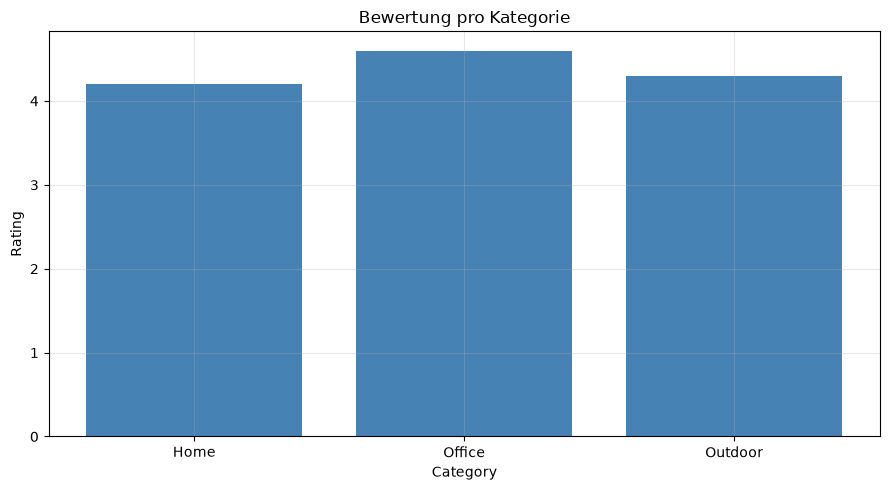

In [32]:
avg = raw.groupby('category')['rating'].mean().dropna()

fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(
    avg.index,
    avg.values,
    color="steelblue"
)

ax.set_xlabel("Category")
ax.set_ylabel("Rating")
ax.set_title("Bewertung pro Kategorie")
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Teil C – Datenaufbereitung und EDA

### C1 (4 P)
Erstellen Sie `clean`: Preise als float (Komma und Punkt akzeptieren), Ratings als float und ungültige Werte als NaN. Entfernen Sie keine Produkte.

In [23]:
# Ihre Lösung

### C2 (4 P)
Berechnen Sie je Kategorie: Produktanzahl, Durchschnittspreis und Median der gültigen Ratings. Sortieren Sie nach Durchschnittspreis absteigend.

In [24]:
# Ihre Lösung

### C3 (4 P)
Lesen Sie `feedback.json` ein und zeigen Sie, wie viele positive und negative Rückmeldungen vorliegen. Erstellen Sie anschliessend einen geeigneten Plot.

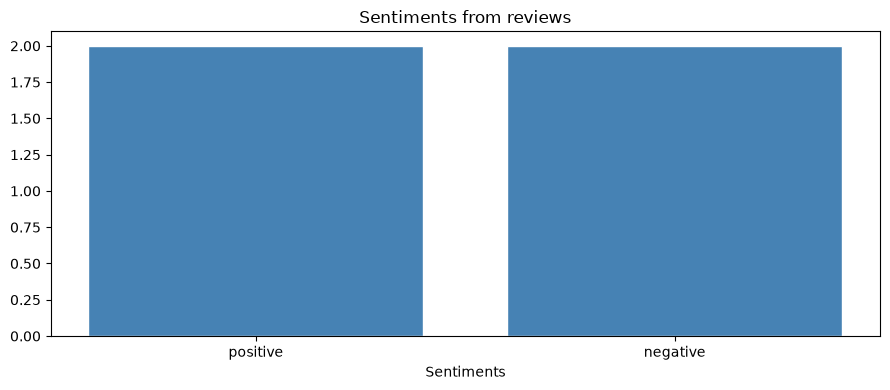

In [38]:
# Ihre Lösung
df_f = pd.read_json("feedback.json")

snetiments = df_f['sentiment'].value_counts()

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(snetiments.index,
        snetiments.values,
        color='steelblue',
        edgecolor='white')
ax.set_xlabel('Sentiments')
ax.set_title('Sentiments from reviews')
plt.tight_layout()
plt.show()
